In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast

import sys
import os

sys.path.insert(0, os.path.join(os.getcwd(), "..", "scripts"))
from utility_functions import overlap, charge, AD_coords, non_overlap_ADs_count, overlap_AD_count

In [2]:
# Read in predictions from individual predictors
individual_predictions = pd.read_csv('arnold_seqs_with_ADs_combined_all_six.csv',
                                     index_col=0, 
                                     converters={'combined_preds' : ast.literal_eval, 
                                                })

# Convert to lists of tuples
individual_predictions['adhunter_intervals'] = individual_predictions['adhunter_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['tada_intervals'] = individual_predictions['tada_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adpred_intervals'] = individual_predictions['adpred_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['paddle_intervals'] = individual_predictions['paddle_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['adhunter_ensemble_intervals'] = individual_predictions['adhunter_ensemble_intervals'].fillna('[]').apply(ast.literal_eval)
individual_predictions['composition_intervals'] = individual_predictions['composition_intervals'].fillna('[]').apply(ast.literal_eval)

In [3]:
individual_predictions['name'].value_counts()

name
HLH3B_FBtr0070506      1
HLH54F_FBtr0089547     1
CG1620_FBtr0300830     1
CG17186_FBtr0083858    1
slou_FBtr0084123       1
GATAd_FBtr0079993      1
sim_FBtr0082710        1
gem_FBtr0089759        1
toy_FBtr0089185        1
CG16778_FBtr0100126    1
H_FBtr0083916          1
CG3726_FBtr0070858     1
cas_FBtr0078725        1
otp_FBtr0110772        1
srp_FBtr0100595        1
rn_FBtr0300518         1
exex_FBtr0076751       1
CG8388_FBtr0087263     1
ac_FBtr0070072         1
lbe_FBtr0084091        1
Kr-h1_FBtr0079195      1
Eip78C_FBtr0306158     1
Doc2_FBtr0076547       1
CG30431_FBtr0085991    1
Cf2_FBtr0304887        1
MTF-1_FBtr0113324      1
wor_FBtr0080740        1
sage_FBtr0081982       1
CG14451_FBtr0078538    1
bin_FBtr0076900        1
pdm2_FBtr0080392       1
Hnf4_FBtr0079747       1
Bteb2_FBtr0070735      1
rgr_FBtr0088692        1
E2f_FBtr0084119        1
ey_FBtr0089235         1
CG10321_FBtr0071660    1
Clk_FBtr0076785        1
Hr39_FBtr0081481       1
pzg_FBtr0078336     

In [4]:
individual_predictions[individual_predictions['name'] == 'sage_FBtr0081982']

,name,sequence,adhunter_centers,adhunter_preds,tada_centers,tada_preds,adpred_preds,paddle_centers,paddle_preds,adhunter_ensemble_centers,adhunter_ensemble_preds,adhunter_ensemble_uncertainty,combined_preds,adhunter_intervals,tada_intervals,adpred_intervals,paddle_intervals,adhunter_ensemble_intervals,composition_intervals
2,sage_FBtr0081982,MTDQLLSSTAGVPGDPPPVLVPVSATTGGPYLSGGSEGEAESSEQP...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[30880.996,29525.176,28409.023,25637.508,22340...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.19404547,0.18928748,0.17743398,0.16912003,0...","[0.002590855,0.002430137,0.002195323,0.0018545...","[27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,...","[0.6459617,0.66534346,0.6576664,0.64576685,0.6...","[27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,...","[-0.581023633480072,-0.6113008260726929,-0.480...",[],"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",[],[],[],[],[],[]


In [5]:
# Not sure why there are so many duplicates, wrote my fasta wrong??
individual_predictions = individual_predictions.drop_duplicates(['name', 'sequence']).reset_index(drop=True)

In [6]:
# Read in parrot model predictions
with open('arnold_seqs_consensus_all_six_preds.tsv', 'r') as f:
    lines = f.readlines()

names = []
seqs = []
pred_ls = []

for line in lines: 
    line = line.split()
    name = line[0]
    seq = line[1]
    preds = line[2:]
    preds = [float(p) for p in preds]
    names.append(name)
    seqs.append(seq)
    pred_ls.append(preds)

consensus_preds = pd.DataFrame({'name' : names, 'sequence' : seqs, 'preds' : pred_ls})

In [7]:
len(consensus_preds)

49

In [8]:
# Read in experimental data
data = pd.read_csv('arnold_seqs_with_short_ADs.csv', index_col=0)
data['ad_charge'] = data['tAD sequence [aa]'].apply(charge)

In [9]:
# Sequences with multiple ADs have multiple rows
len(data.drop_duplicates(['TF_name']))

49

In [10]:
# Merge predictions
merged_individual = individual_predictions.merge(data, left_on=['name', 'sequence'], right_on=['TF_name', 'protein_seq'], how='right')
merged_consensus = consensus_preds.merge(data, left_on=['sequence'], right_on=['protein_seq'], how='right') 

In [11]:
# Get AD coordinates from parrot model
merged_consensus['predicted_AD_coords'] = merged_consensus['preds'].apply(AD_coords)

(-0.1, 1.4)

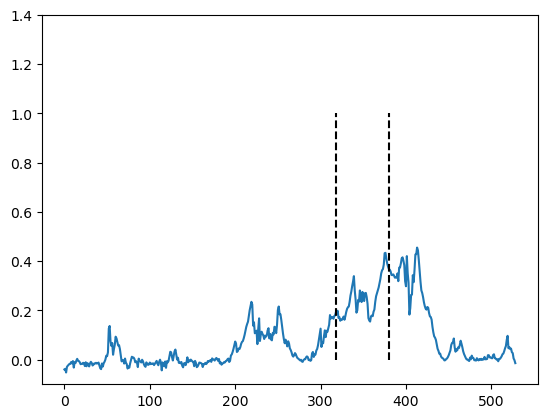

In [12]:
plt.plot(merged_consensus.loc[52, 'preds'])
plt.vlines(merged_consensus.loc[52, 'start tAD [relative to TF CDS]']/3, 0, 1, color='black', linestyles='--')
plt.vlines(merged_consensus.loc[52, 'end tAD [relative to TF CDS]']/3, 0, 1, color='black', linestyles='--')
plt.ylim(-0.1, 1.4)

In [ ]:
# ANOTHER ERROR: WE ARE DOUBLE COUNTING MISSED ADS on the same sequence

In [13]:
merged_consensus['start'] = merged_consensus["start tAD [relative to TF CDS]"] / 3
merged_consensus['end'] = merged_consensus["end tAD [relative to TF CDS]"] / 3
merged_consensus['overlap'] = merged_consensus.apply(overlap_AD_count, axis=1)
merged_consensus['no_overlap'] = merged_consensus.apply(non_overlap_ADs_count, axis=1)

merged_individual['start'] = merged_individual["start tAD [relative to TF CDS]"] / 3
merged_individual['end'] = merged_individual["end tAD [relative to TF CDS]"] / 3

# Get intervals for individual predictors
# merged_individual['adhunterlite_overlap'] = merged_individual.apply(overlap, ad_coords_col='adhunter_intervals', axis=1)
# merged_individual['tada_overlap'] = merged_individual.apply(overlap, ad_coords_col='tada_intervals', axis=1)
# merged_individual['adpred_overlap'] = merged_individual.apply(overlap, ad_coords_col='adpred_intervals', axis=1)
# merged_individual['paddle_overlap'] = merged_individual.apply(overlap, ad_coords_col='paddle_intervals', axis=1)
# merged_individual['composition_overlap'] = merged_individual.apply(overlap, ad_coords_col='composition_intervals', axis=1)
# merged_individual['adhunterensemble_overlap'] = merged_individual.apply(overlap, ad_coords_col='adhunter_ensemble_intervals', axis=1)

merged_individual['adhunterlite_overlap'] = merged_individual.apply(overlap_AD_count, ad_coords_col='adhunter_intervals', axis=1)
merged_individual['tada_overlap'] = merged_individual.apply(overlap_AD_count, ad_coords_col='tada_intervals', axis=1)
merged_individual['adpred_overlap'] = merged_individual.apply(overlap_AD_count, ad_coords_col='adpred_intervals', axis=1)
merged_individual['paddle_overlap'] = merged_individual.apply(overlap_AD_count, ad_coords_col='paddle_intervals', axis=1)
merged_individual['composition_overlap'] = merged_individual.apply(overlap_AD_count, ad_coords_col='composition_intervals', axis=1)
merged_individual['adhunterensemble_overlap'] = merged_individual.apply(overlap_AD_count, ad_coords_col='adhunter_ensemble_intervals', axis=1)

# Get ADs that don't overlap individual predictors
merged_individual['adhunterlite_no_overlap'] = merged_individual.apply(non_overlap_ADs_count, ad_coords_col='adhunter_intervals', axis=1)
merged_individual['tada_no_overlap'] = merged_individual.apply(non_overlap_ADs_count, ad_coords_col='tada_intervals', axis=1)
merged_individual['adpred_no_overlap'] = merged_individual.apply(non_overlap_ADs_count, ad_coords_col='adpred_intervals', axis=1)
merged_individual['paddle_no_overlap'] = merged_individual.apply(non_overlap_ADs_count, ad_coords_col='paddle_intervals', axis=1)
merged_individual['composition_no_overlap'] = merged_individual.apply(non_overlap_ADs_count, ad_coords_col='composition_intervals', axis=1)
merged_individual['adhunterensemble_no_overlap'] = merged_individual.apply(non_overlap_ADs_count, ad_coords_col='adhunter_ensemble_intervals', axis=1)

In [14]:
# Calculate recall (TP / total Positive)
adpred_r = len(merged_individual[merged_individual['adpred_overlap'] > 0]) / len(merged_individual)
tada_r = len(merged_individual[merged_individual['tada_overlap'] > 0]) / len(merged_individual)
adhunterlite_r = len(merged_individual[merged_individual['adhunterlite_overlap'] > 0]) / len(merged_individual)
adhunterensemble_r = len(merged_individual[merged_individual['adhunterensemble_overlap'] > 0]) / len(merged_individual)
paddle_r = len(merged_individual[merged_individual['paddle_overlap'] > 0]) / len(merged_individual)
composition_r = len(merged_individual[merged_individual['composition_overlap'] > 0]) / len(merged_individual)
parrot_r = len(merged_consensus[merged_consensus['overlap'] > 0]) / len(merged_consensus)


In [53]:
# Calculate precision
# ADs that overlap versus those that don't overlap

# Calculate recall (TP / total Positive)
adpred_p = len(merged_individual[merged_individual['adpred_overlap'] > 0]) / (len(merged_individual[merged_individual['adpred_overlap'] > 0]) + len(merged_individual[merged_individual['adpred_no_overlap'] > 0]))
tada_p = len(merged_individual[merged_individual['tada_overlap'] > 0]) / (len(merged_individual[merged_individual['tada_overlap'] > 0]) + len(merged_individual[merged_individual['tada_no_overlap'] > 0]))
adhunterlite_p = len(merged_individual[merged_individual['adhunterlite_overlap'] > 0]) / (len(merged_individual[merged_individual['adhunterlite_overlap'] > 0]) + len(merged_individual[merged_individual['adhunterlite_no_overlap'] > 0]))
adhunterensemble_p = len(merged_individual[merged_individual['adhunterensemble_overlap'] > 0]) / (len(merged_individual[merged_individual['adhunterensemble_overlap'] > 0]) + len(merged_individual[merged_individual['adhunterensemble_no_overlap'] > 0]))
paddle_p = len(merged_individual[merged_individual['paddle_overlap'] > 0]) / (len(merged_individual[merged_individual['paddle_overlap'] > 0]) + len(merged_individual[merged_individual['paddle_no_overlap'] > 0]))
composition_p = len(merged_individual[merged_individual['composition_overlap'] > 0]) / (len(merged_individual[merged_individual['composition_overlap'] > 0]) + len(merged_individual[merged_individual['composition_no_overlap'] > 0]))
parrot_p = len(merged_consensus[merged_consensus['overlap'] > 0]) / (len(merged_consensus[merged_consensus['overlap'] > 0]) + len(merged_individual[merged_consensus['no_overlap'] > 0]))

In [16]:
len(merged_individual[merged_individual['adhunterensemble_overlap'] > 0]) # 1 AD that overlaps

(len(merged_individual[merged_individual['adhunterensemble_overlap'] > 0]) + sum(merged_individual['adhunterensemble_no_overlap'])) # 26 ADs total


26

In [17]:
merged_individual[merged_individual['adhunterensemble_overlap'] > 0][['start', 'end', 'adhunterensemble_overlap',]]

,start,end,adhunterensemble_overlap
1,165.0,344.0,1
7,64.0,157.0,1
19,217.0,483.0,1
24,246.0,374.0,1
29,293.0,389.0,1
46,598.0,677.0,1


In [45]:
merged_consensus[['predicted_AD_coords', 'overlap', 'no_overlap', 'start', 'end']]

,predicted_AD_coords,overlap,no_overlap,start,end
0,[],0,0,101.0,306.0
1,"[(239, 270), (276, 291)]",2,0,165.0,344.0
2,[],0,0,58.0,134.0
3,[],0,0,194.0,264.0
4,[],0,0,544.0,628.0
5,[],0,0,573.0,637.0
6,[],0,0,545.0,685.0
7,"[(0, 153)]",1,0,64.0,157.0
8,[],0,0,178.0,268.0
9,[],0,0,169.0,225.0


In [22]:
def calculate_f1(presicion, recall): 
    return 2* (presicion * recall) / (presicion + recall)

In [54]:
adpred_f1 = calculate_f1(adpred_p, adpred_r)
tada_f1 = calculate_f1(tada_p, tada_r)
adhunterlite_f1 = calculate_f1(adhunterlite_p, adhunterlite_r)
adhunterensemble_f1 = calculate_f1(adhunterensemble_p, adhunterensemble_r)
paddle_f1 = calculate_f1(paddle_p, paddle_r)
composition_f1 = calculate_f1(composition_p, composition_r)
parrot_f1 = calculate_f1(parrot_p, parrot_r)

In [55]:
print("Model\tprecision\trecall\t")
print(f'ADpred\t{adpred_p:.3}\t{adpred_r:.3}\t{adpred_f1:.3}')
print(f'TADA\t{tada_p:.3}\t{tada_r:.3}\t{tada_f1:.3}')
print(f'ADhunterLite\t{adhunterlite_p:.3}\t{adhunterlite_r:.3}\t{adhunterlite_f1:.3}')
print(f'ADhunterEnsemble\t{adhunterensemble_p:.3}\t{adhunterensemble_r:.3}\t{adhunterensemble_f1:.3}')
print(f'PADDLE\t{paddle_p:.3}\t{paddle_r:.3}\t{paddle_f1:.3}')
print(f'Composition\t{composition_p:.3}\t{composition_r:.3}\t{composition_f1:.3}')
print(f'Parrot consensus\t{parrot_r:.3}\t{parrot_p:.3}\t{parrot_f1:.3}')

Model	precision	recall	
ADpred	0.407	0.208	0.275
TADA	0.421	0.453	0.436
ADhunterLite	0.418	0.434	0.426
ADhunterEnsemble	0.316	0.113	0.167
PADDLE	0.531	0.321	0.4
Composition	0.429	0.17	0.243
Parrot consensus	0.151	0.381	0.216


In [25]:
(merged_individual.loc[20, 'adpred_no_overlap'])

np.int64(1)

In [50]:
len(merged_individual[merged_individual['adhunterensemble_overlap'] > 0])

6

In [27]:
len(ast.literal_eval(merged_individual.loc[20, 'paddle_preds']))

1257

In [28]:
len(merged_individual.loc[20, 'combined_preds'])

1309

In [29]:
max(merged_individual.loc[20, 'combined_preds'])

0.8333333333333334

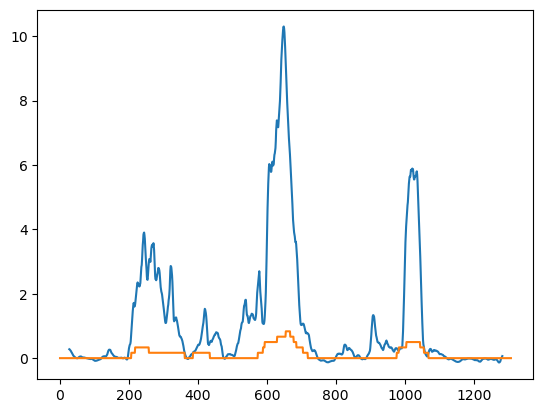

In [30]:
plt.plot(ast.literal_eval(merged_individual.loc[20, 'paddle_centers']), ast.literal_eval(merged_individual.loc[20, 'paddle_preds']))
plt.plot(merged_individual.loc[20, 'combined_preds'])

# Making plots

In [42]:
merged_consensus.columns

Index(['name_x', 'sequence_x', 'preds', 'TF_name',
       'start tAD [relative to TF CDS]', 'end tAD [relative to TF CDS]',
       'tAD length [aa]', 'tAD sequence [aa]', 'enrichment (log2)', 'P-value',
       'FDR', 'Pfam', 'seg', 'cast (score >=40)', 'fLPS - SINGLE',
       'fLPS - MULTIPLE', 'fLPS - WHOLE', 'EMBOSS pepstats charge', 'name_y',
       'sequence_y', 'cds', 'protein_seq', 'ad_charge', 'predicted_AD_coords',
       'start', 'end', 'overlap', 'no_overlap'],
      dtype='object')

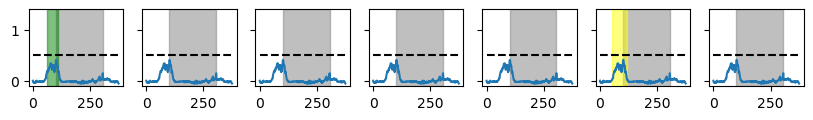

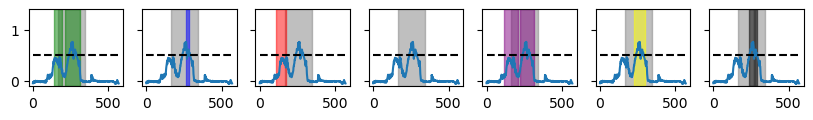

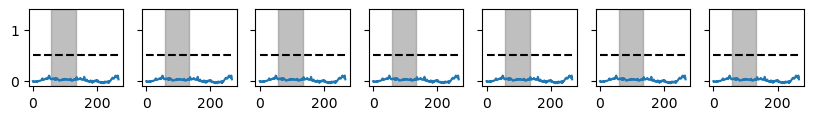

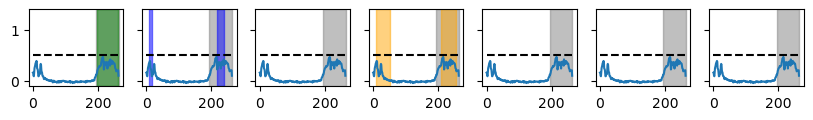

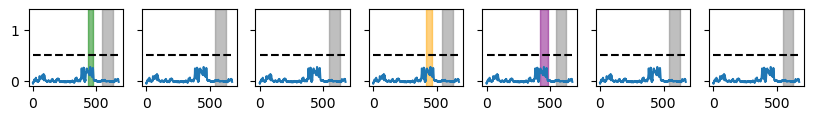

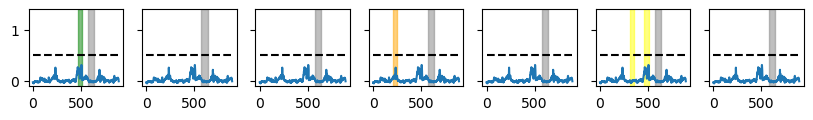

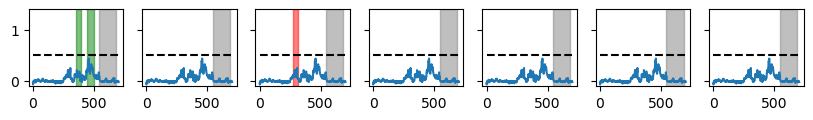

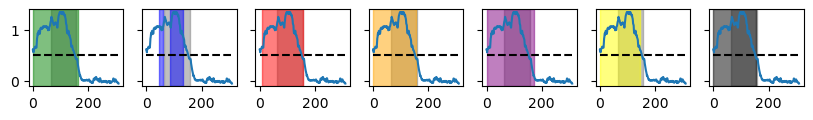

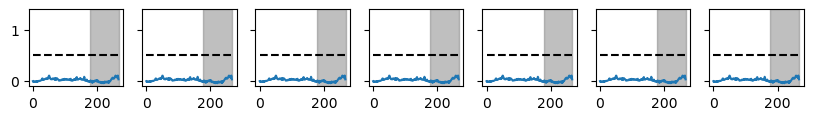

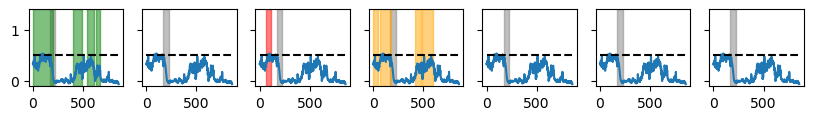

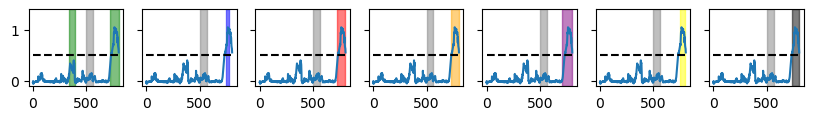

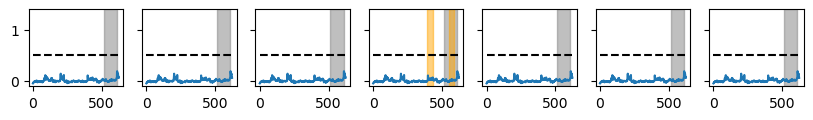

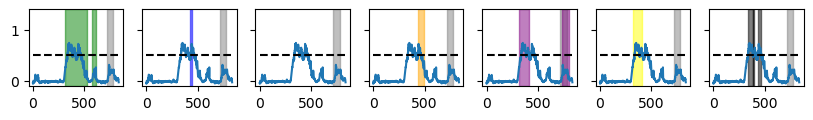

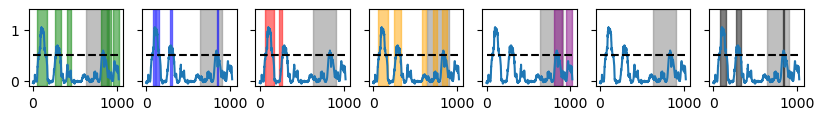

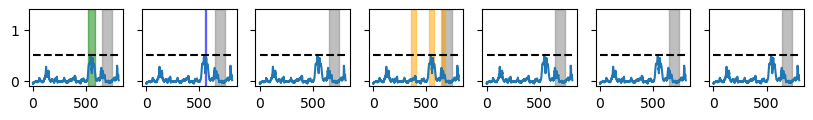

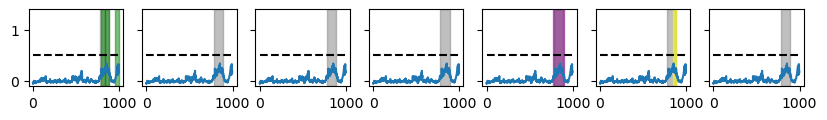

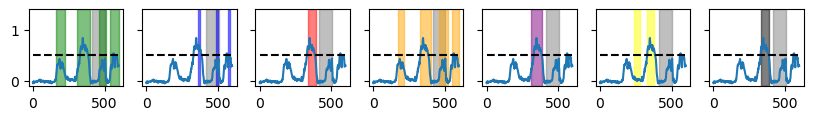

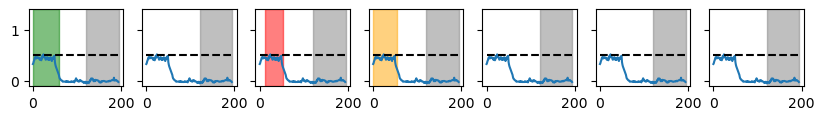

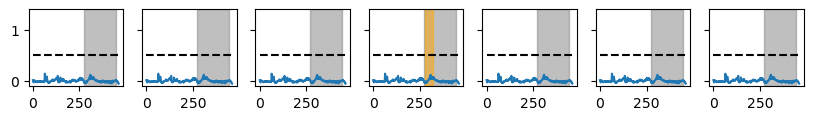

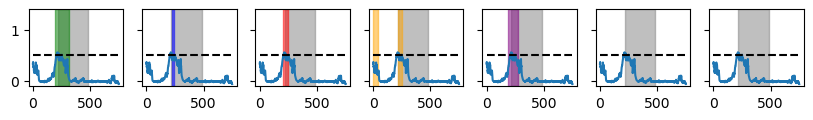

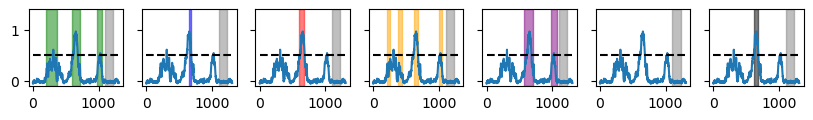

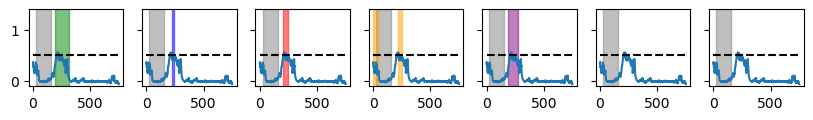

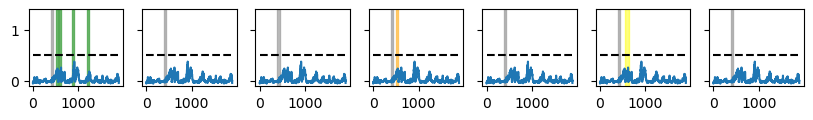

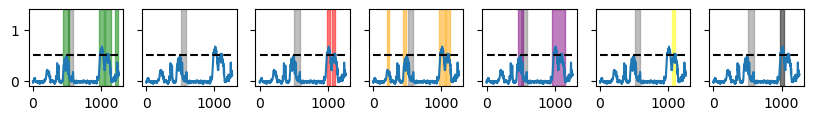

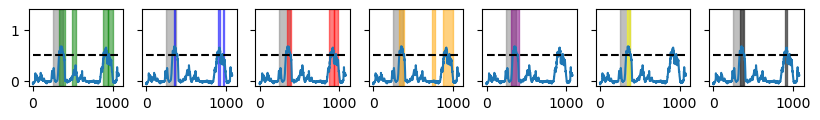

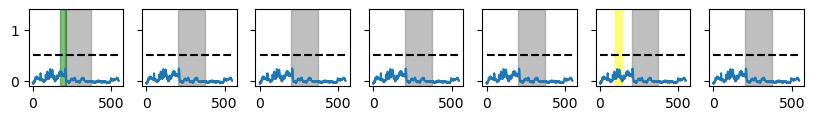

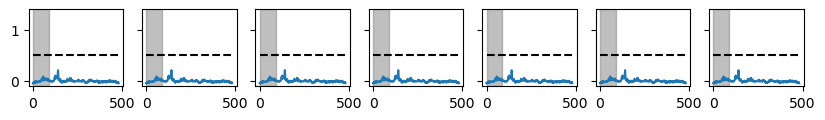

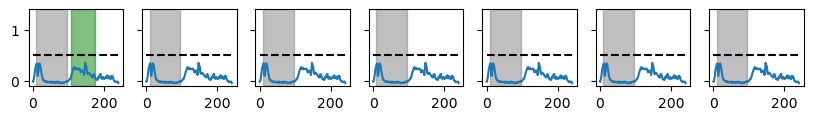

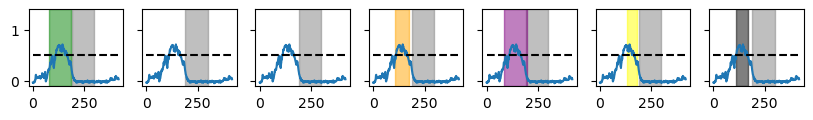

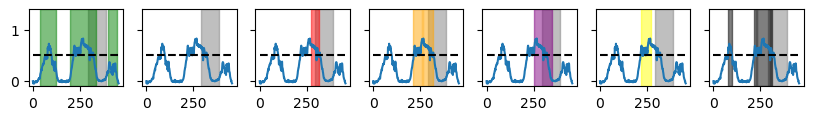

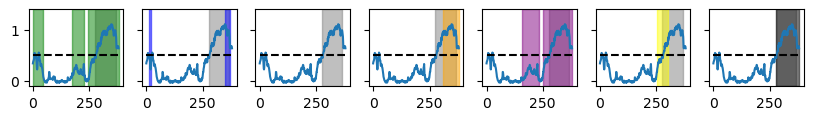

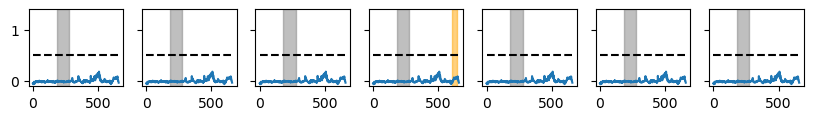

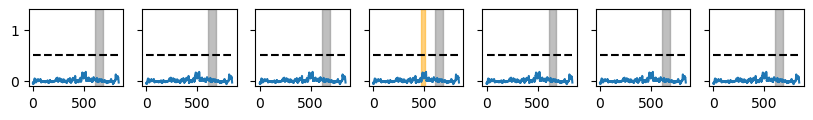

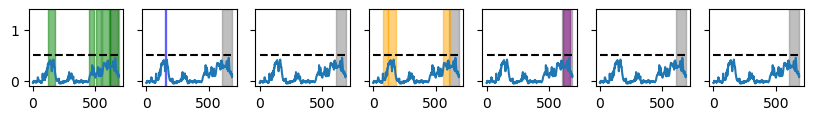

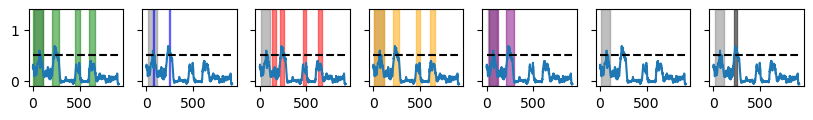

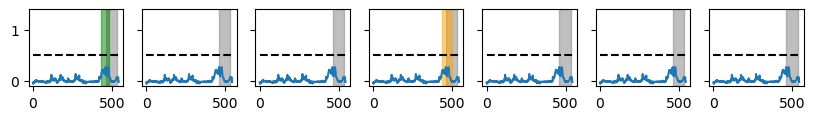

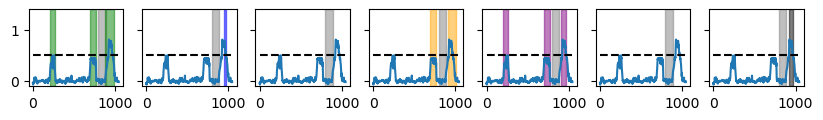

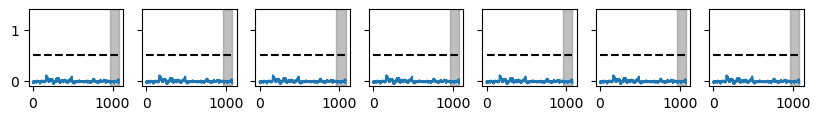

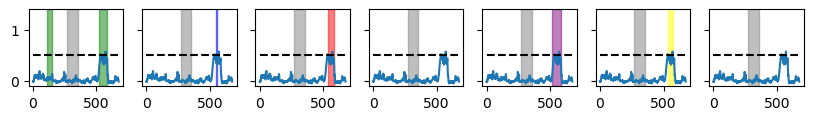

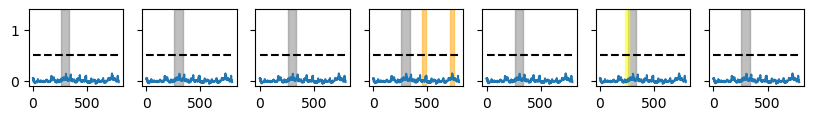

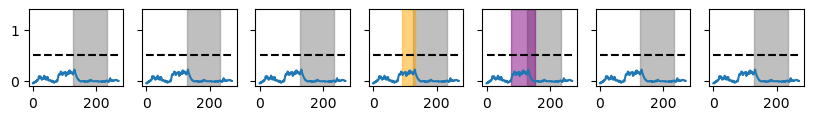

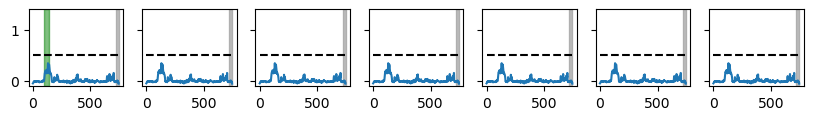

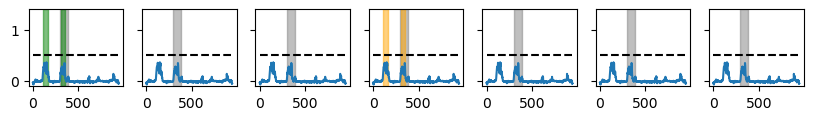

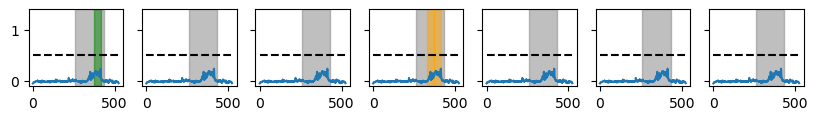

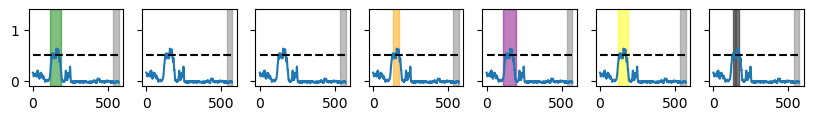

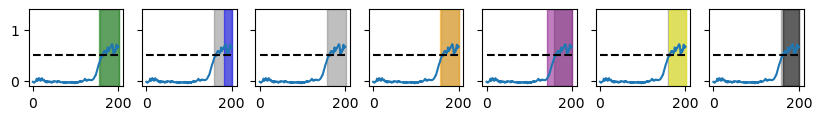

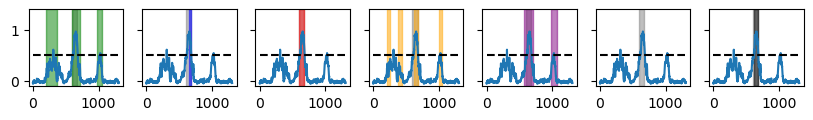

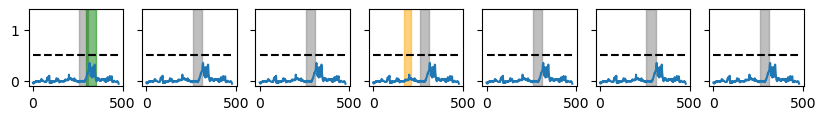

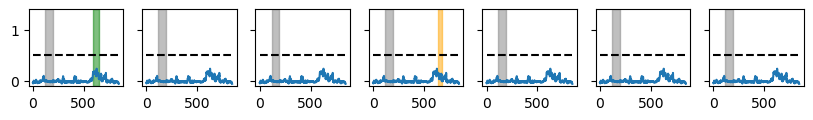

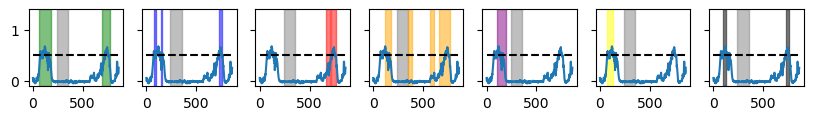

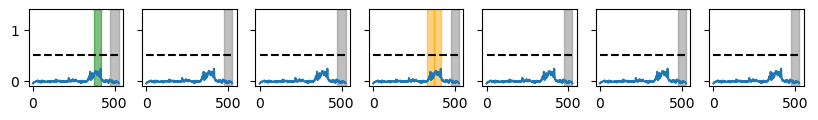

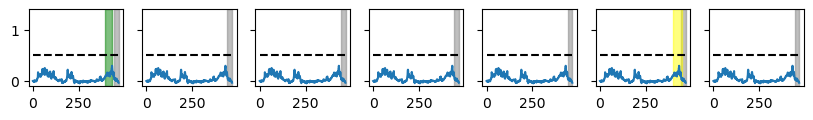

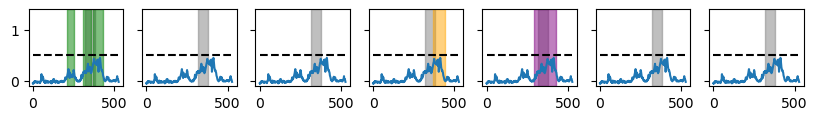

In [43]:
for i in range(len(merged_consensus)): 
    fig, axs = plt.subplots(1, 7, figsize=(10, 1), sharey=True)
    for j in range(7):
        axs[j].plot(merged_consensus.loc[i, 'preds'])
        axs[j].axvspan(merged_consensus.loc[i, 'start'], merged_consensus.loc[i, 'end'], color='grey', alpha=0.5)
        axs[j].hlines(0.5, 0, len(merged_consensus.loc[i, 'protein_seq']), color='black', linestyle='--')

    for start, end in merged_individual.loc[i, 'tada_intervals']: 
        axs[0].axvspan(start, end, color='green', alpha=0.5)
    
    for start, end in merged_individual.loc[i, 'adpred_intervals']: 
        axs[1].axvspan(start, end, color='blue', alpha=0.5)

    for start, end in merged_individual.loc[i, 'adhunter_ensemble_intervals']: 
        axs[2].axvspan(start, end, color='red', alpha=0.5)

    for start, end in merged_individual.loc[i, 'adhunter_intervals']: 
        axs[3].axvspan(start, end, color='orange', alpha=0.5)

    for start, end in merged_individual.loc[i, 'paddle_intervals']: 
        axs[4].axvspan(start, end, color='purple', alpha=0.5)
    
    for start, end in merged_individual.loc[i, 'composition_intervals']: 
        axs[5].axvspan(start, end, color='yellow', alpha=0.5)

    for start, end in merged_consensus.loc[i, 'predicted_AD_coords']: 
        axs[6].axvspan(start, end, color='black', alpha=0.5)



    axs[0].set_ylim(-0.1, 1.4)
    plt.show()